In [1]:
import matplotlib
import numpy as np
import librosa
import os
import csv
import pandas as pd

In [20]:
# 

# def rename_files_in_directory(directory, start_index):
#     renamed_files = []
#     try:
#         files = [f for f in os.listdir(directory) if f.endswith('.m4a')]
#         for index, filename in enumerate(files, start=start_index):
#             new_name = f"data_{index}.m4a"
#             old_path = os.path.join(directory, filename)
#             new_path = os.path.join(directory, new_name)
#             os.rename(old_path, new_path)
#             print(f"Renamed {old_path} to {new_path}")
#             renamed_files.append((new_name, directory))
#         return start_index + len(files), renamed_files
#     except Exception as e:
#         print(f"An error occurred in directory {directory}: {e}")
#         return start_index, renamed_files

# def rename_files_in_directories(directories):
#     current_index = 0
#     all_renamed_files = []
#     for directory in directories:
#         current_index, renamed_files = rename_files_in_directory(directory, current_index)
#         all_renamed_files.extend(renamed_files)
#     return all_renamed_files

# def write_to_csv(file_data, csv_filename):
#     with open(csv_filename, mode='w', newline='') as file:
#         writer = csv.writer(file)
#         writer.writerow(['name', 'class'])
#         writer.writerows(file_data)
#     print(f"CSV file {csv_filename} created successfully.")


In [21]:
# # List of directories
# directories = [
#     "./data/far_loud",
#     "./data/far_normal",
#     "./data/far_small",
#     "./data/near_loud",
#     "./data/near_normal",
#     "./data/near_small"
# ]

# renamed_files_data = rename_files_in_directories(directories)

# csv_filename = 'renamed_files.csv'
# write_to_csv(renamed_files_data, 'data.csv')

Renamed ./data/far_loud/동백꽃 : 멀리 : 큰 소리.m4a to ./data/far_loud/data_0.m4a
Renamed ./data/far_loud/인어공주 멀리서 속삭임.m4a to ./data/far_loud/data_1.m4a
Renamed ./data/far_loud/애국가 : 멀리 : 큰 소리.m4a to ./data/far_loud/data_2.m4a
Renamed ./data/far_loud/아무말 : 멀리 : 큰 소리.m4a to ./data/far_loud/data_3.m4a
Renamed ./data/far_loud/인어공주 멀리서 크게.m4a to ./data/far_loud/data_4.m4a
Renamed ./data/far_loud/동백꽃 : 멀리 : 큰 소리 2.m4a to ./data/far_loud/data_5.m4a
Renamed ./data/far_loud/성냥 : 멀리 : 큰 소리.m4a to ./data/far_loud/data_6.m4a
Renamed ./data/far_normal/동백꽃 - 멀리 - 평음.m4a to ./data/far_normal/data_7.m4a
Renamed ./data/far_normal/동백꽃 : 멀리 : 평음 2.m4a to ./data/far_normal/data_8.m4a
Renamed ./data/far_normal/애국가 : 멀리 : 평음.m4a to ./data/far_normal/data_9.m4a
Renamed ./data/far_normal/동백꽃 : 멀리 : 평음.m4a to ./data/far_normal/data_10.m4a
Renamed ./data/far_normal/아무말 : 멀리 : 

In [2]:
import os
import librosa
import numpy as np
import csv

def extract_features(file_path):
    try:
        y, sr = librosa.load(file_path)
        # Extract features
        mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
        chroma = librosa.feature.chroma_stft(y=y, sr=sr)
        mel = librosa.feature.melspectrogram(y=y, sr=sr)
        contrast = librosa.feature.spectral_contrast(y=y, sr=sr)
        tonnetz = librosa.feature.tonnetz(y=y, sr=sr)
        
        # Aggregate features
        features = np.concatenate((
            np.mean(mfccs, axis=1),
            np.std(mfccs, axis=1),
            np.mean(chroma, axis=1),
            np.std(chroma, axis=1),
            np.mean(mel, axis=1),
            np.std(mel, axis=1),
            np.mean(contrast, axis=1),
            np.std(contrast, axis=1),
            np.mean(tonnetz, axis=1),
            np.std(tonnetz, axis=1)
        ))
        return features
    except Exception as e:
        print(f"Error processing {file_path}: {e}")
        return None

def process_directory(directory):
    feature_list = []
    files = [f for f in os.listdir(directory) if f.endswith('.m4a')]
    for filename in files:
        file_path = os.path.join(directory, filename)
        features = extract_features(file_path)
        if features is not None:
            class_label = directory.split('/')[-1]  # Use the directory name as the class label
            feature_list.append([filename, class_label] + features.tolist())
    return feature_list

def process_directories(directories):
    all_features = []
    for directory in directories:
        features = process_directory(directory)
        all_features.extend(features)
    return all_features

def write_features_to_csv(features, csv_filename):
    headers = ['filename', 'class'] + [f'feature_{i}' for i in range(1, len(features[0]) - 1)]
    with open(csv_filename, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(headers)
        writer.writerows(features)
    print(f"CSV file {csv_filename} created successfully.")

# List of directories
directories = [
    "far_loud",
    "far_normal",
    "far_small",
    "near_loud",
    "near_normal",
    "near_small"
]

# Process directories and extract features
all_features = process_directories(directories)

# Write features to CSV
csv_filename = 'audio_features.csv'
write_features_to_csv(all_features, csv_filename)

/var/folders/4g/nt6b468n5_189y9n400s1wkc0000gn/T/ipykernel_97631/1916284496.py:8: UserWarning: PySoundFile failed. Trying audioread instead.
  y, sr = librosa.load(file_path)
/opt/homebrew/anaconda3/envs/grad/lib/python3.9/site-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)
/var/folders/4g/nt6b468n5_189y9n400s1wkc0000gn/T/ipykernel_97631/1916284496.py:8: UserWarning: PySoundFile failed. Trying audioread instead.
  y, sr = librosa.load(file_path)
/opt/homebrew/anaconda3/envs/grad/lib/python3.9/site-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


CSV file audio_features.csv created successfully.


In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
import joblib

# Load the features from CSV
data = pd.read_csv('audio_features.csv')

# Assuming the last column 'class' is your target and all other columns are features
X = data.drop(columns=['filename', 'class'])
y = data['class']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize the model
model = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the model
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy}")
print("Classification Report:")
print(report)

# Save the model
joblib.dump(model, 'audio_classification_model.joblib')
print("Model saved as audio_classification_model.joblib")

Accuracy: 0.75
Classification Report:
              precision    recall  f1-score   support

    far_loud       1.00      0.50      0.67         2
  far_normal       0.00      0.00      0.00         0
   far_small       0.50      1.00      0.67         1
 near_normal       1.00      1.00      1.00         3
  near_small       1.00      0.50      0.67         2

    accuracy                           0.75         8
   macro avg       0.70      0.60      0.60         8
weighted avg       0.94      0.75      0.79         8

Model saved as audio_classification_model.joblib


/opt/homebrew/anaconda3/envs/grad/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1517: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/homebrew/anaconda3/envs/grad/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1517: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/homebrew/anaconda3/envs/grad/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1517: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.utils import to_categorical

# Load the features from CSV
data = pd.read_csv('audio_features.csv')

# Separate features and target
X = data.drop(columns=['filename', 'class'])
y = data['class']

# Encode the target labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
y_categorical = to_categorical(y_encoded)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y_categorical, test_size=0.2, random_state=42)

# Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Build the neural network model
model = Sequential([
    Dense(128, input_shape=(X_train.shape[1],), activation='relu'),
    Dropout(0.5),
    Dense(64, activation='relu'),
    Dropout(0.5),
    Dense(len(label_encoder.classes_), activation='softmax')
])

# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Train the model
history = model.fit(X_train_scaled, y_train, epochs=50, batch_size=32, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(X_test_scaled, y_test)
print(f"Test Accuracy: {accuracy}")

# Save the model
model.save('audio_classification_model.h5')
print("Model saved as audio_classification_model.h5")

Epoch 1/50


/opt/homebrew/anaconda3/envs/grad/lib/python3.9/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 387ms/step - accuracy: 0.2083 - loss: 2.1433 - val_accuracy: 0.0000e+00 - val_loss: 1.8643
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.2500 - loss: 1.9920 - val_accuracy: 0.1429 - val_loss: 1.6937
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.2917 - loss: 1.7582 - val_accuracy: 0.2857 - val_loss: 1.5755
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.1667 - loss: 2.2308 - val_accuracy: 0.4286 - val_loss: 1.5042
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.2917 - loss: 1.8095 - val_accuracy: 0.4286 - val_loss: 1.4650
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.3750 - loss: 1.6975 - val_accuracy: 0.4286 - val_loss: 1.4536
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.2917 - loss: 1.4939 - val_accuracy: 0.4286 - val_loss: 1.4415
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.3333 - loss: 1.5509 - val_accuracy: 0.4286 - val_loss: 1.4249
Epoch 

Test Accuracy: 0.75
Model saved as audio_classification_model.h5


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Classification Report on Training Data:
              precision    recall  f1-score   support

    far_loud       0.67      0.86      0.75         7
  far_normal       0.83      0.83      0.83         6
   far_small       0.71      1.00      0.83         5
   near_loud       1.00      0.71      0.83         7
 near_normal       1.00      0.86      0.92         7
  near_small       1.00      0.86      0.92         7

    accuracy                           0.85        39
   macro avg       0.87      0.85      0.85        39
weighted avg       0.88      0.85      0.85        39



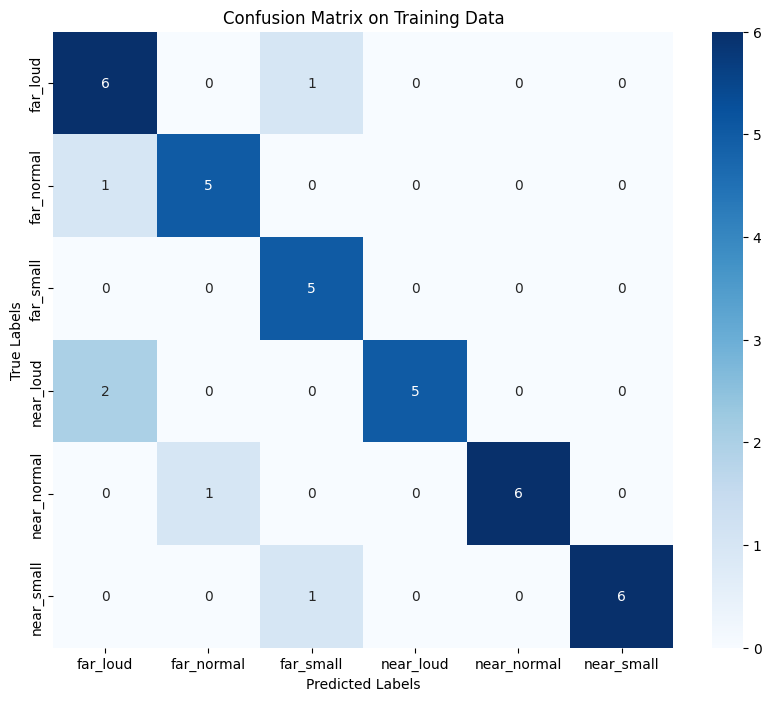

In [10]:
# 모델에 학습시킨 데이터로 예측

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model

# Load the features from CSV
data = pd.read_csv('audio_features.csv')

# Separate features and target
X = data.drop(columns=['filename', 'class'])
y = data['class']

# Encode the target labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Load the scaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Load the trained model
model = load_model('audio_classification_model.h5')

# Make predictions on the training data
y_pred_prob = model.predict(X_scaled)
y_pred = np.argmax(y_pred_prob, axis=1)

# Decode the predicted and actual labels
y_pred_labels = label_encoder.inverse_transform(y_pred)
y_true_labels = label_encoder.inverse_transform(y_encoded)

# Generate a classification report
report = classification_report(y_true_labels, y_pred_labels)
print("Classification Report on Training Data:")
print(report)

# Generate a confusion matrix
conf_matrix = confusion_matrix(y_true_labels, y_pred_labels, labels=label_encoder.classes_)

# Plot the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix on Training Data')
plt.show()
